# Homework 8.1 - Task 1

## Two-Mode Diffusion Schedule and Compatible Forward Dynamics

We use the one-dimensional symmetric target

$$
y_1=-2,
\qquad
y_2=2.
$$

Let

$$
T=1
$$

and choose the initial component standard deviation

$$
\sigma_0=0.25.
$$

The time-dependent density is

$$
p_t(x)
=
\frac{1}{2}N(x;\alpha(t)y_1,\sigma(t)^2)
+
\frac{1}{2}N(x;\alpha(t)y_2,\sigma(t)^2).
$$

At $t=0$, the density is concentrated near the two target points.

At $t=1$, both Gaussian components become the same standard Gaussian.

## 1. Schedule

Use the finite-endpoint schedule suggested in the course book:

$$
\alpha(t)
=
\cos\left(\frac{\pi t}{2}\right).
$$

Let

$$
q=1-\sigma_0^2.
$$

Choose

$$
\sigma(t)^2
=
1-q\alpha(t)^2.
$$

Then

$$
\alpha(0)=1,
\qquad
\alpha(1)=0,
$$

and

$$
\sigma(0)=\sigma_0,
\qquad
\sigma(1)=1.
$$

Therefore

$$
p_1(x)=N(x;0,1).
$$

## 2. Compatible affine forward SDE

For an affine drift

$$
f(x,t)=b(t)x
$$

and scalar diffusion $g(t)$, compatibility requires

$$
\alpha'(t)=b(t)\alpha(t)
$$

and

$$
\frac{d}{dt}\sigma(t)^2
=
2b(t)\sigma(t)^2+g(t)^2.
$$

For $t<1$,

$$
b(t)
=
-\frac{\pi}{2}
\tan\left(\frac{\pi t}{2}\right),
$$

and

$$
g(t)^2
=
\pi
\tan\left(\frac{\pi t}{2}\right).
$$

Thus

$$
g(t)^2=-2b(t).
$$

These SDE coefficients diverge as $t$ approaches 1.

The density itself does not become singular.

Our convention is:

- retain the exact endpoint density $p_1=N(0,1)$ analytically;
- never initialize or evaluate the forward SDE exactly at $t=1$;
- for reverse generation, use the probability-flow ODE in an analytically stabilized form whose endpoint limit is finite.

In [12]:
from pathlib import Path
import json
import math

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

cwd = Path.cwd()
PROJECT_ROOT = cwd.parent if cwd.name.lower() == "codes" else cwd

DATA_DIR = PROJECT_ROOT / "data" / "hw8_1"
RESULT_DIR = PROJECT_ROOT / "result images" / "hw8_1"

DATA_DIR.mkdir(parents=True, exist_ok=True)
RESULT_DIR.mkdir(parents=True, exist_ok=True)

T = 1.0
Y1 = -2.0
Y2 = 2.0
A = 2.0
SIGMA0 = 0.25
Q = 1.0 - SIGMA0**2

CONFIG = {
    "dimension": 1,
    "T": T,
    "y1": Y1,
    "y2": Y2,
    "a": A,
    "sigma0": SIGMA0,
    "q": Q,
    "schedule": "alpha=cos(pi*t/2), sigma^2=1-q*alpha^2",
    "endpoint_convention": (
        "Use exact p_T=N(0,1); never evaluate singular forward SDE "
        "coefficients at t=1; use stabilized probability-flow velocity "
        "with continuous endpoint extension for reverse generation."
    ),
}

config_path = DATA_DIR / "task1_configuration.json"
config_path.write_text(
    json.dumps(CONFIG, indent=2),
    encoding="utf-8",
)

print(json.dumps(CONFIG, indent=2))
print("Saved:", config_path.resolve())

{
  "dimension": 1,
  "T": 1.0,
  "y1": -2.0,
  "y2": 2.0,
  "a": 2.0,
  "sigma0": 0.25,
  "q": 0.9375,
  "schedule": "alpha=cos(pi*t/2), sigma^2=1-q*alpha^2",
  "endpoint_convention": "Use exact p_T=N(0,1); never evaluate singular forward SDE coefficients at t=1; use stabilized probability-flow velocity with continuous endpoint extension for reverse generation."
}
Saved: C:\Users\benja\OneDrive\Univeristy of Alabama courses\Math 638\Project 2\HW8.1\data\hw8_1\task1_configuration.json


In [13]:
def alpha(t):
    t = np.asarray(t, dtype=float)
    return np.cos(
        0.5 * np.pi * t
    )


def alpha_prime(t):
    t = np.asarray(t, dtype=float)
    return (
        -0.5
        * np.pi
        * np.sin(
            0.5 * np.pi * t
        )
    )


def variance(t):
    a = alpha(t)
    return (
        1.0
        - Q * a**2
    )


def sigma(t):
    return np.sqrt(
        variance(t)
    )


def variance_prime(t):
    a = alpha(t)
    ap = alpha_prime(t)

    return (
        -2.0
        * Q
        * a
        * ap
    )


def b_coefficient(t):
    t = np.asarray(t, dtype=float)

    return (
        -0.5
        * np.pi
        * np.tan(
            0.5 * np.pi * t
        )
    )


def g_squared(t):
    t = np.asarray(t, dtype=float)

    return (
        np.pi
        * np.tan(
            0.5 * np.pi * t
        )
    )

## 3. Numerical verification of the marginal equations

The equations are checked on a dense grid strictly below the singular endpoint.

The residuals are

$$
r_\alpha
=
\alpha'-b\alpha
$$

and

$$
r_\sigma
=
\frac{d}{dt}\sigma^2
-
2b\sigma^2
-
g^2.
$$

For the chosen schedule, both should be zero up to floating-point error.

In [14]:
t_check = np.linspace(
    0.0,
    1.0 - 1e-8,
    100_000,
)

r_alpha = (
    alpha_prime(t_check)
    - b_coefficient(t_check)
    * alpha(t_check)
)

r_variance = (
    variance_prime(t_check)
    - 2.0
    * b_coefficient(t_check)
    * variance(t_check)
    - g_squared(t_check)
)

verification = {
    "max_abs_alpha_equation_residual": float(
        np.max(np.abs(r_alpha))
    ),
    "max_abs_variance_equation_residual": float(
        np.max(np.abs(r_variance))
    ),
    "min_g_squared_on_check_grid": float(
        np.min(g_squared(t_check))
    ),
    "alpha_0": float(alpha(0.0)),
    "alpha_1": float(alpha(1.0)),
    "sigma_0": float(sigma(0.0)),
    "sigma_1": float(sigma(1.0)),
}

verification_path = (
    DATA_DIR
    / "task1_marginal_equation_verification.json"
)

verification_path.write_text(
    json.dumps(
        verification,
        indent=2,
    ),
    encoding="utf-8",
)

print(
    json.dumps(
        verification,
        indent=2,
    )
)

{
  "max_abs_alpha_equation_residual": 4.440892098500626e-16,
  "max_abs_variance_equation_residual": 2.9802322387695312e-08,
  "min_g_squared_on_check_grid": 0.0,
  "alpha_0": 1.0,
  "alpha_1": 6.123233995736766e-17,
  "sigma_0": 0.25,
  "sigma_1": 1.0
}


## 4. Exact mixture density

For mean magnitude

$$
m(t)=2\alpha(t)
$$

and variance

$$
v(t)=\sigma(t)^2,
$$

the density is

$$
p_t(x)
=
\frac{1}{2}N(x;-m(t),v(t))
+
\frac{1}{2}N(x;m(t),v(t)).
$$

In [15]:
def normal_density(
    x,
    mean,
    var,
):
    x = np.asarray(
        x,
        dtype=float,
    )

    return (
        np.exp(
            -0.5
            * (x - mean)**2
            / var
        )
        / np.sqrt(
            2.0
            * np.pi
            * var
        )
    )


def mixture_density(
    x,
    t,
):
    m = A * alpha(t)
    v = variance(t)

    return (
        0.5
        * normal_density(
            x,
            -m,
            v,
        )
        + 0.5
        * normal_density(
            x,
            m,
            v,
        )
    )

## 5. Validate density normalization and moments

For the symmetric equal-weight mixture,

$$
E[X_t]=0
$$

and

$$
Var(X_t)=m(t)^2+v(t).
$$

We verify these claims numerically by quadrature.

In [16]:
x_grid = np.linspace(
    -8.0,
    8.0,
    200_001,
)

check_times = [
    0.0,
    0.25,
    0.50,
    0.75,
    0.90,
    0.99,
    1.0,
]

rows = []

for t in check_times:
    p = mixture_density(
        x_grid,
        t,
    )

    mass = np.trapz(
        p,
        x_grid,
    )

    mean_num = np.trapz(
        x_grid * p,
        x_grid,
    )

    second_num = np.trapz(
        x_grid**2 * p,
        x_grid,
    )

    m = A * alpha(t)
    var_exact = (
        m**2
        + variance(t)
    )

    rows.append({
        "t": t,
        "numerical_mass": mass,
        "numerical_mean": mean_num,
        "numerical_second_moment": second_num,
        "exact_variance": var_exact,
        "second_moment_abs_error": abs(
            second_num
            - var_exact
        ),
    })


density_validation = pd.DataFrame(
    rows
)

density_validation_path = (
    DATA_DIR
    / "task1_density_validation.csv"
)

density_validation.to_csv(
    density_validation_path,
    index=False,
)

print(
    density_validation.to_string(
        index=False
    )
)

   t  numerical_mass  numerical_mean  numerical_second_moment  exact_variance  second_moment_abs_error
0.00             1.0    1.104471e-16                 4.062500        4.062500             8.881784e-16
0.25             1.0    1.116738e-16                 3.614007        3.614007             4.440892e-16
0.50             1.0    2.488664e-17                 2.531250        2.531250             4.440892e-16
0.75             1.0    5.958925e-17                 1.448493        1.448493             2.218226e-13
0.90             1.0   -1.243697e-17                 1.074945        1.074945             2.469136e-13
0.99             1.0   -1.127883e-18                 1.000756        1.000756             8.371082e-14
1.00             1.0    4.052203e-17                 1.000000        1.000000             8.215650e-14


## 6. Plot the density at several times

The figure should show the two data modes gradually approaching one another and eventually becoming the standard Gaussian.

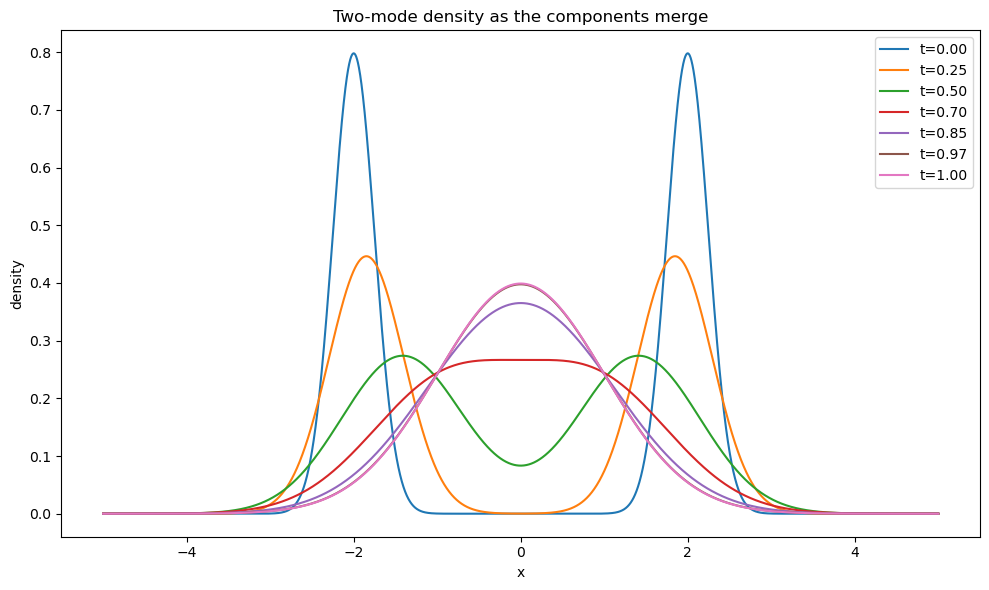

Saved: C:\Users\benja\OneDrive\Univeristy of Alabama courses\Math 638\Project 2\HW8.1\result images\hw8_1\task1_density_evolution.png


In [17]:
plot_times = [
    0.0,
    0.25,
    0.50,
    0.70,
    0.85,
    0.97,
    1.0,
]

x_plot = np.linspace(
    -5.0,
    5.0,
    4000,
)

plt.figure(
    figsize=(10, 6)
)

for t in plot_times:
    plt.plot(
        x_plot,
        mixture_density(
            x_plot,
            t,
        ),
        label=f"t={t:.2f}",
    )

plt.xlabel("x")
plt.ylabel("density")
plt.title(
    "Two-mode density as the components merge"
)
plt.legend()
plt.tight_layout()

path = (
    RESULT_DIR
    / "task1_density_evolution.png"
)

plt.savefig(
    path,
    dpi=200,
)

plt.show()

print("Saved:", path.resolve())

# Task 1 Conclusion

The schedule satisfies the required marginal equations for $t<1$.

The final density is exactly the standard Gaussian, while the chosen forward SDE coefficients are singular at the endpoint.

This is a schedule singularity, not a density singularity.

Task 2 derives and validates the exact score of the Gaussian mixture.